In [23]:
from market_making_agent import config, _get_likelihoods, _get_gm_quotes, update_beliefs, _get_terminal_values, 
import numpy as np
import matplotlib.pyplot as plt

test_config = config.copy()

test_config["signal"] = 0.0
test_config["kyle_beta"] = 10.0

values = np.array([4.0, 6.0])
probs = np.array([0.5, 0.5])

bid = 4.8
ask = 5.2
mu = 0.20

p_buy, p_sell = _get_likelihoods(
    values, bid, ask, mu, test_config
)

print("Buy likelihoods:", p_buy)
print("Sell likelihoods:", p_sell)

assert np.allclose(p_buy, [0.4, 0.6])
assert np.allclose(p_sell, [0.6, 0.4])

print("TEST 1 PASSED")

Buy likelihoods: [0.4 0.6]
Sell likelihoods: [0.6 0.4]
TEST 1 PASSED


In [12]:
bid, ask, buy_probs, sell_probs = _get_gm_quotes(
    values, probs, p_buy, p_sell, test_config
)

print("Bid:", bid)
print("Ask:", ask)
print("Buy posterior:", buy_probs)
print("Sell posterior:", sell_probs)

assert np.isclose(bid, 4.8)
assert np.isclose(ask, 5.2)

assert np.allclose(buy_probs, [0.4, 0.6])
assert np.allclose(sell_probs, [0.6, 0.4])

assert np.isclose(np.sum(buy_probs), 1)
assert np.isclose(np.sum(sell_probs), 1)

print("TEST 2 PASSED")

Bid: 4.800000000000001
Ask: 5.200000000000001
Buy posterior: [0.4 0.6]
Sell posterior: [0.6 0.4]
TEST 2 PASSED


In [14]:
p_buy, p_sell = _get_likelihoods(
    values, 4.8, 5.2, 0.0, test_config
)

bid, ask, buy_probs, sell_probs = _get_gm_quotes(
    values, probs, p_buy, p_sell, test_config
)

assert np.isclose(bid, 5.0)
assert np.isclose(ask, 5.0)

assert np.allclose(buy_probs, probs)
assert np.allclose(sell_probs, probs)

print("TEST 3 PASSED")

TEST 3 PASSED


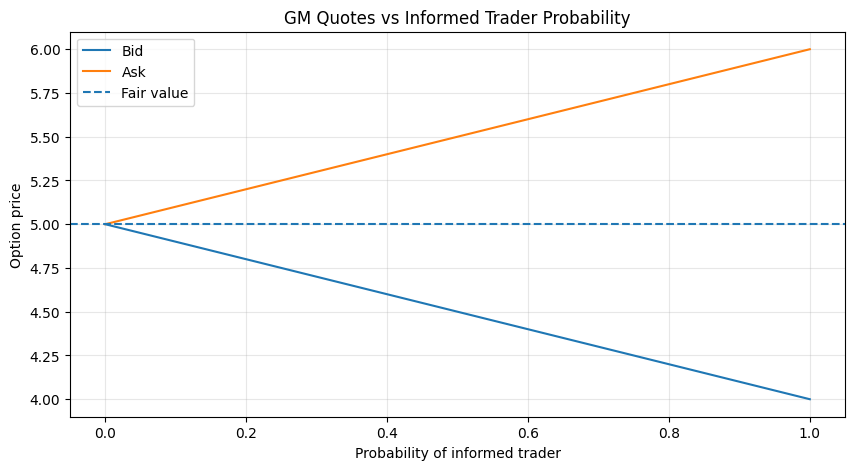

TEST 4 PASSED


In [17]:
mu_values = np.linspace(0, 1, 101)

bids = []
asks = []
spreads = []

for mu in mu_values:

    p_buy, p_sell = _get_likelihoods(
        values, 4.8, 5.2, mu, test_config
    )

    bid, ask, _, _ = _get_gm_quotes(
        values, probs, p_buy, p_sell, test_config
    )

    bids.append(bid)
    asks.append(ask)
    spreads.append(ask - bid)

assert np.all(np.diff(spreads) >= -1e-10)

plt.figure(figsize=(10, 5))

plt.plot(mu_values, bids, label="Bid")
plt.plot(mu_values, asks, label="Ask")
plt.axhline(5, linestyle="--", label="Fair value")

plt.xlabel("Probability of informed trader")
plt.ylabel("Option price")
plt.title("GM Quotes vs Informed Trader Probability")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("TEST 4 PASSED")

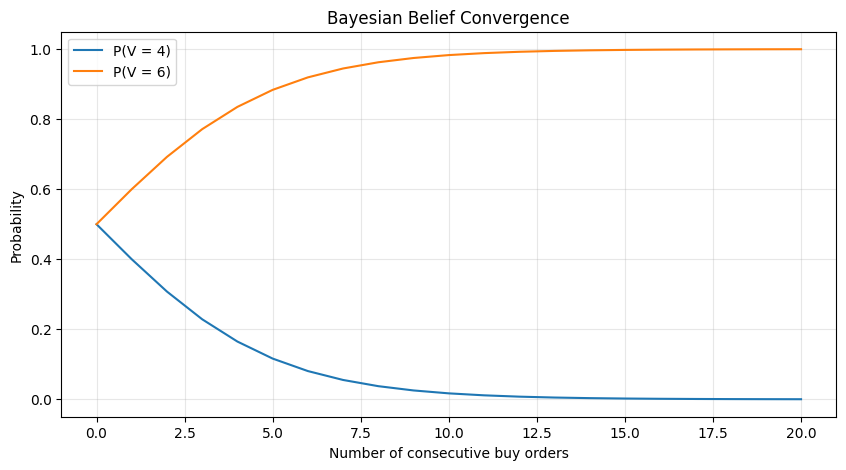

TEST 5 PASSED


In [20]:
values = np.array([4.0, 6.0])
probs = np.array([0.5, 0.5])

mu = 0.20

p_buy, p_sell = _get_likelihoods(
    values, 4.8, 5.2, mu, test_config
)

belief_history = [probs.copy()]

for i in range(20):

    probs = update_beliefs(probs, p_buy)

    belief_history.append(probs.copy())

belief_history = np.array(belief_history)

assert np.allclose(belief_history.sum(axis=1), 1)
assert np.all(np.diff(belief_history[:, 1]) >= 0)

plt.figure(figsize=(10, 5))

plt.plot(belief_history[:, 0], label="P(V = 4)")
plt.plot(belief_history[:, 1], label="P(V = 6)")

plt.xlabel("Number of consecutive buy orders")
plt.ylabel("Probability")
plt.title("Bayesian Belief Convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("TEST 5 PASSED")